## pyPlumeRise Example 1

In this example, we illustrate how pyPlumeRise can be used to simulate a steady eruption column using meteorological data from an online repository.

First, we import PlumeRise package and matplotlib for plotting

In [1]:
import plumerise as pr
%matplotlib inline
import matplotlib.pyplot as plt

To create a simulation we require four sets of data:
- Meteorological data
- Physical parameters
- Solver parameters
- Initial conditions (corresponding to volanic source conditions)

### Meteorological data

The plume model requires atmospheric profiles.  Specifically, we need:
- altitude above mean sea level
- temperature
- pressure
- wind direction
- wind speed
- relative humidity

These quantities can be specified in a 2D numpy array, with the profiles in columns ordered as:
- column 1: altitude [m]
- column 2: temperature [K]
- column 3: pressure [Pa]
- column 4: wind direction [degrees]
- column 5: wind speed [m/s]
- column 6: relative humidity [dimensionless, in range 0..1]

The data can be obtained from online repositories using methods in pyPlumeRise.  Specifically, we can download data from the *Wyoming Weather Web* repository of upper air soundings, or from the *ECMWF ERA5* repository of reanalysis meteorology.

pyPlumeRise has methods to download and process meteorological data from these sources, using the `MetData` class.

#### Wyoming Weather Web

The [Wymoning Weather Web](https://weather.uwyo.edu/upperair/sounding.html) archives upper air radiosonde soundings from global meteorological stations.

<div class="warning" style='background-color:#d6eaf8; color:#478ec5; border-left: solid #478ec5 4px; padding:0.1em;'>
    <span>
        <h4>Note</h4>
        <p>Downloading from Wyoming Weather Web requires a response from the remote server.</p>
        <p>If this fails, try rerunning the command, and <a href="https://weather.uwyo.edu/upperair/sounding.html">check</a> that the server is online.</p>
    </span>
</div>

To download Wyoming Weather Web data, we need to specify a date (string in format YYYY-MM-DD) and time (string in format HH:MM UTC; data in the repository is stored at 00:00 and 12:00).  Additionally, we need to specify the station identifier (string of form #####), which can be found from Wyoming Weather Web.

A `MetData` object containing Wyoming Weather Web data is initialized using a call of the form
<code>
    MetData(date, time, 'radiosonde', source='wyoming', stationID=ID)
</code>

#### ECMWF ERA5

The [ERA5](https://confluence.ecmwf.int/display/CKB/ERA5%3A+data+documentation) repository contains global reanalysis meteorological data, at 0.25 degrees resolution, for the period January 1940 to the present.

<div class="warning" style='background-color:#d6eaf8; color:#478ec5; border-left: solid #478ec5 4px; padding:0.1em;'>
    <span>
        <h4>Note</h4>
        <p>Downloading from ERA5 requires a CDS API key.  See <a>https://cds.climate.copernicus.eu/api-how-to</a></p>
        <p>The CDS server will queue the request, which may take some time to complete.</p>
    </span>
</div>

To download ERA5 data, we need to specify a location (latitude and longitude in decimal degrees), a date (string in format YYYY-MM-DD) and time (string in format HH:MM).

A `MetData` object is initialized using a call of the form
<code>
    MetData(date, time, 'era5', latitude=lat, longitude=lon)
</code>

In this example we use data from Wyoming Weather Web, from Keflavik airport, Iceland.

In [2]:
WYO = pr.MetData('2010-04-14', '12:00', 'radiosonde', source='wyoming', stationID="04018")

To use this data in PlumeRise, we convert to the numpy array format, using the method `to_array()`

In [3]:
Met = WYO.to_array()

### Physical Parameters

The PlumeRise model contains several physical parameters that must be specified.  The method `set_params()` can be used to initialize, returning a numpy array.

The table below gives the parameters with their symbol and default value.

|Symbol|Default value|Parameter [unit]|
|------|-------------|----------------|
|g|9.81|gravitational acceleration [m/s<sup>2</sup>]|
|rhos|1200.0|density of solids [kg/m<sup>3</sup>]|
|rhow|1000.0|density of liquid water [kg/m<sup>3</sup>]|
|rhoi|900.0|density of ice [kg/m<sup>3</sup>]|
|Ca|998.0|Specific heat capacities of dry air [J/kg/K]|
|Cs|1617.0|Specific heat capacities of solids [J/kg/K]|
|Cv|1850.0|Specific heat capacities of water vapour [J/kg/K]|
|Cw|4200.0|Specific heat capacities of liquid water[J/kg/K]|
|Ci|1850.0|Specific heat capacities of ice [J/kg/K]|
|Ra|285.0|Specific gas constants of dry air  [J/kg/K]|
|Rv|462.0|Specific gas constants of water vapour [J/kg/K]|
|Lvt0|2.50e6|Latent heat of vapourization at 0 deg C [J/kg]|
|Lmt0|3.34e6|Latent heat of melting at 0 deg C [J/kg]|
|ks|0.09|No-wind Entrainment coefficient [1]|
|kw|0.9|Wind Entrainment coefficient [1]|
|Ti0|263.15|Ice temperature bounds [K].  No ice for T>Ti0, mixed water and ice for Ti00<T<Ti0, all ice for T<Ti00|
|Ti00|233.15|Ice temperature bounds [K].  No ice for T>Ti0, mixed water and ice for Ti00<T<Ti0, all ice for T<Ti00|

To change a parameter, call `set_params()` with the new value.  For example, the change the two entrainment coefficients, call `set_params(ks=0.1, kw=0.5)`

If default parameters are required, call `set_params()` with no arguments.

In [4]:
Params = pr.set_params()

### Solver Parameters

Settings for the numerical solver can be changed using the `set_solver_params()` method.

The table below gives the solver parameters with their symbol and default value.

|Symbol|Default value|Parameter|
|------|-------------|----------------|
|sMax| 100.0e3 | End point of integration, so eventually integration will stop |
|Umin| 1.0e-3 | Minimum rise speed. |
|MaxHorizDistance| 100e3 | Maximum horizontal distance from source. |
|rtol| 1.0e-6 | Relative error tolerance |
|MinStep| 1.0e-8 | Minimum Runge-Kutta step size |
|MaxStep| 1 | Maximum Runge-Kutta step size |
|InitStep| 1.0e-3 | Initial Runge-Kutta step size |
|OutStep| 100.0 | Output step size |
|MaxSolnPnts| 100000 | Maximum number of solution points allowed by the solver. |

To change a parameter, call `set_solver_params()` with the new value.  For example, the change the solver tolerance, call `set_solver_params(rtol=1e-8)`

If default parameters are required, call `set_solver_params()` with no arguments.

In [5]:
SolParams = pr.set_solver_params(eqn='dry')

### Initial (eruption source) conditions

The initial condition for the simulation, that represent the eruption source conditions, are specified using the `set_IC()` method.

The table below gives the initial condition with their symbol and default value.

|Symbol|Default value|Parameter|
|------|-------------|---------|
|L0| 100.0 | vent radius [m] |
|U0| 100.0 | exit velocity [m/s] |
|n0| 0.05 | gas mass fraction [1] |
|T0| 1200.0 | temperature at the vent [K] |
|z0| 0.0 | vent altitude [m] |

To change a parameter, call `set_IC()` with the new value.  For example, the change the vent altitude, call `set_IC(z0=1000)`

If default parameters are required, call `set_IC()` with no arguments.

In [6]:
IC = pr.set_IC(L0=100, U0=100, n0=0.03, T0=1000, z0=1666)

## Running the model

Once the setup is complete, the model can be solved using the `solve()` method, passing the `Params`, `SolParams`, `IC` and `Met` arrays.

Once completed, a message is printed and a solution array is returned.

In [7]:
soln, plume_state, solverFlag = pr.solve(Params=Params,SolParams=SolParams,IC=IC,Met=Met)

Stop condition satisfied


The variables in the solution can be assessed using the `get_soln()` method.  This returns an array with the required variable.  The table below gives the variables available.

|symbol|variable|
|------|--------|
|s| Centreline distance (arclength) [m] |
|x| Easting distance [m] |
|y| Northing distance [m] |
|z| Altitude [m] |
|Q| Mass flux [kg/s] |
|M| Momentum flux [kg m/s] |
|phia| Dry air mass fraction [1] |
|phiv| Water vapour mass fraction [1] |
|phis| Solids mass fraction [1] |
|phiw| Liquid water mass fraction [1] |
|phii| Ice mass fraction [1] |
|Cp| Bulk heat capacity |
|rho| Density [kg/m<sup>3</sup>] |
|T| Temperature [K] |
|theta| Inclination of centreline to x-y plane|
|psi| Angle around z-axis|
|Pa| Atmospheric pressure [Pa]|
|Ta| Atmospheric temperature [K]|
|RH| Atmospheric relative humidity [1]|
|phivA| Atmospheric specific humidity (water vapour fraction) [1]|
|rhoAtm| Atmospheric density [kg/m<sup>3</sup>]|
|V| Atmospheric wind speed [m/s]|
|psia| Atmospheric wind direction|
|L| Top-hat plume radius [m]|
|Lgaussian| Gaussian plume radius [m]|
|U| Top-hat centreline speed [m/s]|
|Ugaussian| Gaussian centreline speed [m/s]|
|E| Enthalpy |
|n| Gas mass fraction |
|Uz| Top-hat vertical speed [m/s]|
|Uzgaussian| Gaussian vertical speed [m/s]|


For example to obtain the plume temperature and vertical velocity as functions of height, as well as the atmospheric temperaure, we would call:

In [11]:
z = pr.get_soln(soln,'z')
L = pr.get_soln(soln,'L')
T = pr.get_soln(soln,'T')
Ta = pr.get_soln(soln,'Ta')
U = pr.get_soln(soln,'U')
Uz = pr.get_soln(soln,'Uz')
phiw = pr.get_soln(soln,'phiw')
Q = pr.get_soln(soln,'Q')
M = pr.get_soln(soln,'M')
rho = pr.get_soln(soln,'rho')

We can then plot these:

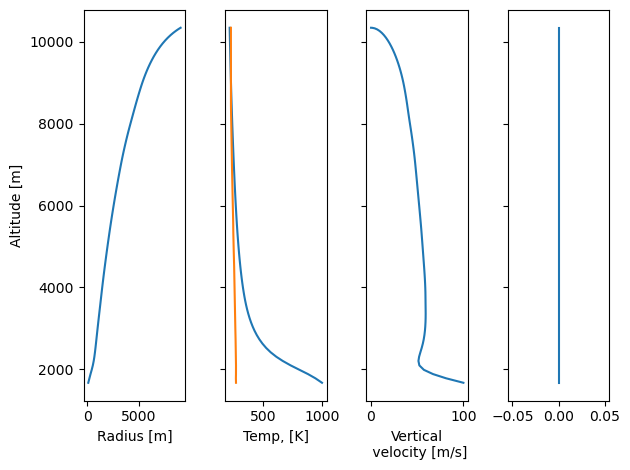

In [12]:
fig, ax = plt.subplots(1,4, sharey=True)
ax[0].plot(L,z)
ax[1].plot(T,z,label='Plume')
ax[1].plot(Ta,z,label='Atmospheric')
ax[2].plot(Uz,z)
ax[3].plot(phiw,z)
_ = ax[0].set_ylabel('Altitude [m]')
_ = ax[0].set_xlabel('Radius [m]')
#_ = ax[0].set_xlim([0,1000])
_ = ax[1].set_xlabel('Temp, [K]')
_ = ax[2].set_xlabel('Vertical\n velocity [m/s]')
fig.tight_layout()